# Ji et al. 2020 — Cutaneous SCC
## 02 · Cell-state manifold — PPT tree, root, pseudotime

Fit a principal tree to the developmental fork. The manifold is **branching** (hub-and-spoke): a Gast/pSom hub diverging into a Gast-leaning arm and a pSom-leaning arm.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


AnnData object with n_obs × n_vars = 7085 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden', 'cycling', 'compartment', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'Gast_sm', 'pSom_sm', 'Crest_sm', 'lz'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'cell_subtype_level1_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'lz', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


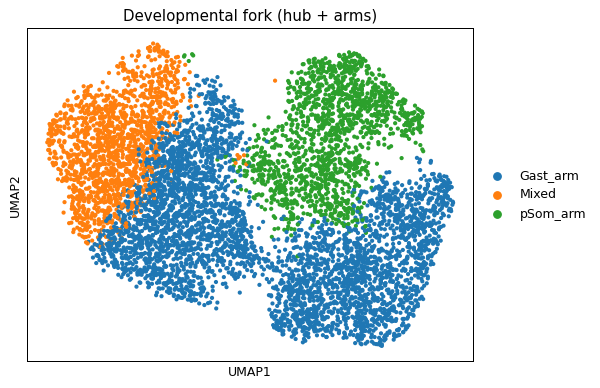

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print(adata)
sc.pl.umap(adata, color='celltype', size=45, title='Developmental fork (hub + arms)'); plt.show()

### Smoothed module geography (kNN-averaged) for reading topology

In [4]:
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for k in ['Gast','pSom','Crest']:
    adata.obs[k+'_sm'] = (A @ adata.obs[k].values) / deg
print('smoothed ranges:', {k:(round(adata.obs[k+'_sm'].min(),2), round(adata.obs[k+'_sm'].max(),2)) for k in ['Gast','pSom','Crest']})

smoothed ranges: {'Gast': (np.float64(-0.11), np.float64(0.09)), 'pSom': (np.float64(-0.04), np.float64(0.18)), 'Crest': (np.float64(-0.1), np.float64(0.1))}


### Fit PPT principal tree
`Nodes=60, ppt_lambda=3000, ppt_sigma=0.5` — scaled to the ~6.8k-cell fork (Filbin used 40/3000 for ~3k cells). The fit yields a clean hub-and-spoke tree: a small number of tips joined through a central branch point.

In [5]:
scf.tl.tree(adata, method='ppt', Nodes=60, ppt_lambda=3000, ppt_sigma=0.5,
            use_rep='X_umap', seed=SEED, plot=False)
B = adata.uns['graph']['B']; d = B.sum(1)
tips = np.where(d==1)[0]; forks = np.where(d>2)[0]
print('tree: %d tips, %d forks (hub-and-spoke)' % (len(tips), len(forks)))
print('tip nodes:', tips.tolist(), '| fork nodes:', forks.tolist())

inferring a principal tree --> parameters used 
    60 principal points, sigma = 0.5, lambda = 3000, metric = euclidean
    fitting:  48%|####8     | 24/50 [00:01<00:01, 17.55it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
tree: 4 tips, 2 forks (hub-and-spoke)
tip nodes: [23, 27, 33, 48] | fork nodes: [47, 52]


### Tree over the smoothed modules — the branch is Gast-vs-pSom
Gast and pSom peak on **different** arms out of the hub; Crest is a terminal readout (high at an arm tip, not at the hub).

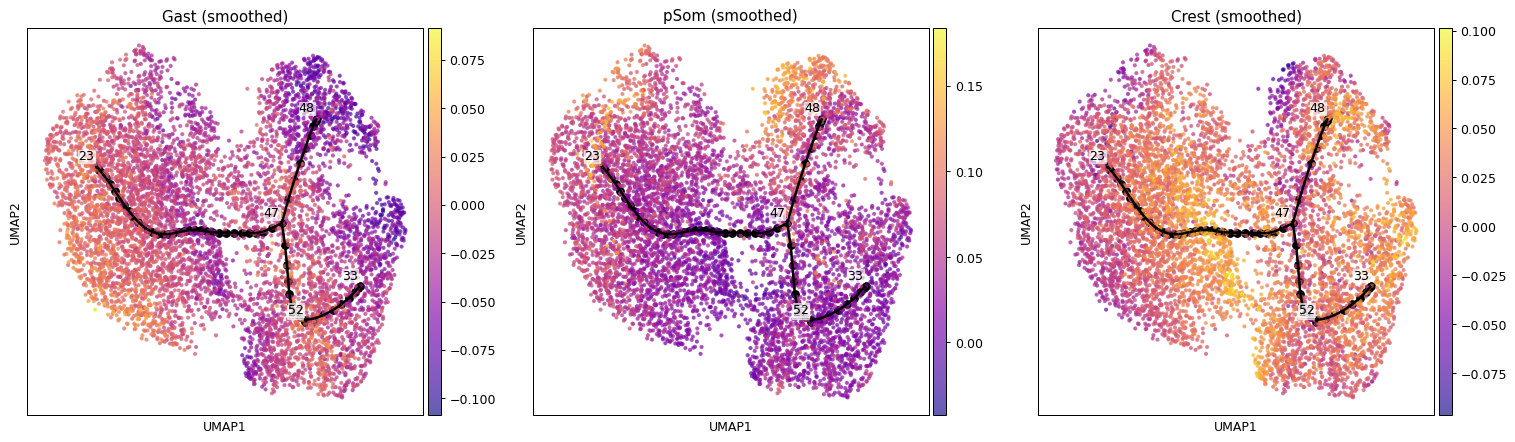

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axs, ['Gast_sm','pSom_sm','Crest_sm']):
    scf.pl.graph(adata, basis='umap', ax=ax, show=False)
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=45, cmap='plasma', alpha=.65)
    ax.set_title(c.replace('_sm',' (smoothed)'))
plt.tight_layout(); plt.show()

### Derive the root — Gast/pSom-high, Crest-low developmental origin
Profile each tip on the nearest 80 cells. Root at the tip maximising (zGast + zpSom − zCrest): the module-convergence origin. Crest is developmentally *late*, so the Crest-high tip is a terminus, never the root (Kürten rooting lesson).

In [7]:
F = adata.uns['graph']['F']
zG = (adata.obs.Gast_sm - adata.obs.Gast_sm.mean())/adata.obs.Gast_sm.std()
zP = (adata.obs.pSom_sm - adata.obs.pSom_sm.mean())/adata.obs.pSom_sm.std()
zC = (adata.obs.Crest_sm - adata.obs.Crest_sm.mean())/adata.obs.Crest_sm.std()
adata.obs['zG']=zG.values; adata.obs['zP']=zP.values; adata.obs['zC']=zC.values
rows = []
for t in tips:
    dd = np.linalg.norm(adata.obsm['X_umap'] - F[:, t], axis=1)
    o = adata.obs.iloc[np.argsort(dd)[:80]]
    rows.append(dict(tip=int(t), zGast=o.zG.mean(), zpSom=o.zP.mean(), zCrest=o.zC.mean(),
                     npat=o['sample'].nunique(), subtype=o.cell_subtype_level1.value_counts().index[0]))
tipdf = pd.DataFrame(rows)
tipdf['root_score'] = tipdf.zGast + tipdf.zpSom - tipdf.zCrest
print(tipdf.round(3).to_string(index=False))
root = int(tipdf.loc[tipdf.root_score.idxmax(), 'tip'])
crest_tip = int(tipdf.loc[tipdf.zCrest.idxmax(), 'tip'])
print('ROOT = tip %d (Gast/pSom-high, Crest-low origin) | Crest-high terminal tip = %d (NOT root)' % (root, crest_tip))

 tip  zGast  zpSom  zCrest  npat       subtype  root_score
  23  0.603  0.214  -0.176     8 Tumor_KC_Diff       0.994
  27  0.283 -0.607   0.097     8  Keratinocyte      -0.420
  33 -0.102 -0.668   0.151     8  Keratinocyte      -0.920
  48 -0.864  0.408   0.071     7  Keratinocyte      -0.527
ROOT = tip 23 (Gast/pSom-high, Crest-low origin) | Crest-high terminal tip = 33 (NOT root)


### Root, pseudotime, rename milestones

In [8]:
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, n_jobs=4, seed=SEED)
mil_ct = adata.obs.groupby('milestones', observed=True)['celltype'].agg(lambda s: s.value_counts().index[0])
mil_t = adata.obs.groupby('milestones', observed=True)['t'].mean()
newnames = {}; seen = {}
for m in mil_t.sort_values().index:
    base = mil_ct[m]
    if base in seen:
        newnames[m] = f'{base}_{seen[base]}'; seen[base]+=1
    else:
        newnames[m] = base; seen[base]=1
scf.tl.rename_milestones(adata, new=newnames)
print('milestone -> (dominant role, mean pseudotime):')
for m in mil_t.sort_values().index:
    print('  %-12s t=%.2f  n=%d' % (newnames[m], mil_t[m], (adata.obs.milestones==newnames[m]).sum()))

node 23 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:04) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
milestone -> (dominant role, mean pseudotime):
  Mixed        t=0.74  n=2067
  Gast_arm     t=4.32  n=1589
  pSom_arm     t=9.31  n=676
  pSom_arm_1   t=11.92  n=940
  Gast_arm_1   t=12.03  n=517
  Gast_arm_2   t=12.28  n=254
  Gast_arm_3   t=13.70  n=1042


### Pseudotime gradients confirm developmental order
Gast/pSom decline and Crest rises along pseudotime from the hub root — the embryonic ordering.

In [9]:
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print('pseudotime rho %-9s = %+.3f' % (m, spearmanr(adata.obs.t, adata.obs[m])[0]))
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
print('caveat: pseudotime vs cycling score rho = %+.2f (cycling scoped out; axis defined by signatures)' % spearmanr(adata.obs.t, np.maximum(g1s,g2m))[0])

pseudotime rho Gast_sm   = -0.499
pseudotime rho pSom_sm   = -0.323
pseudotime rho Crest_sm  = +0.255
caveat: pseudotime vs cycling score rho = +0.08 (cycling scoped out; axis defined by signatures)


### Milestone map

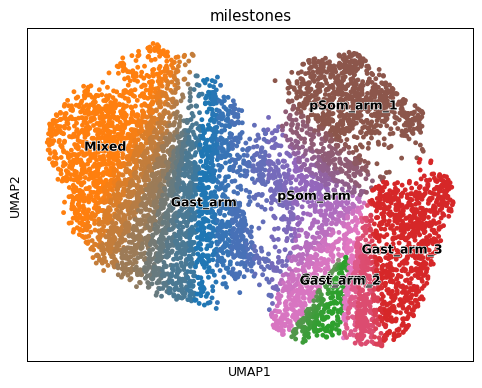

In [10]:
scf.pl.milestones(adata, basis='umap', annotate=True, s=60); plt.show()

In [11]:
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (7085, 21042)


### `manifold.pdf` — cell-state trajectory

saved manifold.pdf | root tip 23


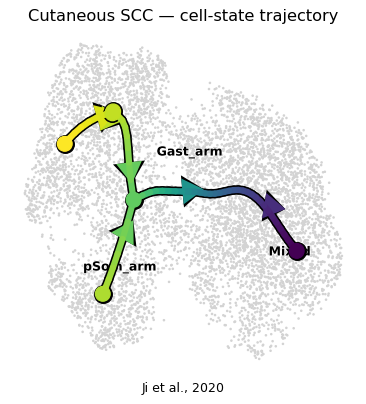

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
scf.pl.trajectory(adata, basis='umap', arrows=True, ax=ax, show=False)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Cutaneous SCC — cell-state trajectory', size=13)
ax.text(.5, -.05, 'Ji et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf | root tip', root)